# 🏡 **Part 1: Preparing Tabular Data (House Price Regression)**

Neural networks cannot read Excel files, and they cannot understand words. They only understand **Tensors**.

In this section, we will take a real-world **House Price Dataset**, clean it, fix any broken data, and transform it into PyTorch Tensors. Our goal is to predict the **Price** of a house based on features like Area, Bedrooms, and Air Conditioning.

### 🔹 **Importing via KaggleHub**
Instead of downloading files manually, we will pull the dataset directly into our Colab environment.

In [ ]:
#!pip install -q kagglehub    # un coment this if kagglehub is not installed

In [ ]:
# Downloading a dataset directly from Kaggle
import kagglehub
import pandas as pd
import torch

print("Downloading House Price dataset from Kaggle...")
path = kagglehub.dataset_download("yasserh/housing-prices-dataset")
print("Path to dataset files:", path)

# Load the CSV directly using the file path
df = pd.read_csv(f"{path}/Housing.csv")

# Let's look at the first 5 houses!
df.head()

Using Colab cache for faster access to the 'housing-prices-dataset' dataset.
Path to dataset files: /kaggle/input/housing-prices-dataset


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


# 🔡 **3. Encoding: Turning Text into Numbers**

Our dataset has text columns like `mainroad` (yes/no) and `furnishingstatus` (furnished, semi-furnished). PyTorch only understands numbers, so we must translate these words.

### 🔹 **Dynamic Label Encoding**
Instead of typing out every single column name manually, we can write a Python script that automatically finds every column containing text (objects) and converts them into numbers using `LabelEncoder`.

In [ ]:
from sklearn.preprocessing import LabelEncoder

# Automatically finding and encoding all text columns
# 1. Find all columns where the data type is "object" (Text)
categorical_cols = df.select_dtypes(include=["object"]).columns

# 2. Loop through them and apply the Label Encoder
for col in categorical_cols:
    print(f"Encoding column: {col}")
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

print("\nSuccess! All text has been converted to numbers.")
df.head()

Encoding column: mainroad
Encoding column: guestroom
Encoding column: basement
Encoding column: hotwaterheating
Encoding column: airconditioning
Encoding column: prefarea
Encoding column: furnishingstatus

Success! All text has been converted to numbers.


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0


# ✂️ **1.5. Handling Outliers (Removing Mansions)**

Neural Networks learn by minimizing the "average" error. If our dataset contains a few $15,000,000 mansions, the model might ruin its predictions for normal, everyday houses just to avoid getting the mansion's price wrong.

These extreme cases are called **Outliers**. To help our model focus on the average homebuyer, let's remove any house priced over **$7,500,000**.

In [ ]:
print(f"Total houses before filtering: {len(df)}")

# *Example*: Filtering rows with multiple conditions in Pandas
# We use the & (AND) symbol to combine our rules.
# We keep ONLY houses where price <= 7.5M AND area <= 8000
df = df[(df['price'] <= 7500000) & (df['area'] <= 8000)]

# Reset the index so our row numbers stay clean (0, 1, 2...)
df = df.reset_index(drop=True)

print(f"Total houses after removing outliers: {len(df)}\n")

# Let's verify our filters worked!
print(f"Highest price remaining: ${df['price'].max():,.2f}")
print(f"Largest area remaining: {df['area'].max():,.0f} sq ft")

Total houses before filtering: 545
Total houses after removing outliers: 456

Highest price remaining: $7,490,000.00
Largest area remaining: 8,000 sq ft


# 🚚 **5. Train/Test Split & PyTorch DataLoaders**

Now that our data is 100% clean, scaled, and numeric, we need to prepare it for the Neural Network.

1. **Train/Test Split**: We split the data (80% Train, 20% Test) so we can evaluate the model on houses it has *never seen before*.
2. **Tensors**: We convert the Pandas dataframes into PyTorch Tensors.
3. **DataLoaders**: We wrap our Tensors in a DataLoader. This acts like a conveyor belt, feeding the data to the GPU in **Batches** (e.g., 32 houses at a time) instead of all at once.

In [ ]:
from sklearn.model_selection import train_test_split

# 1. TRAIN / TEST SPLIT
y = df['price'].values # The Answers
X = df.drop('price', axis=1).values # The Inputs

# Split into 80% Training, 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# 2. CONVERT TO TENSORS
# For Regression, inputs and outputs MUST be float32!
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

# We use .view(-1, 1) to ensure the target is a column matrix [Batch, 1]
# instead of a flat list. This prevents huge Shape Errors later!
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)


In [ ]:

from torch.utils.data import TensorDataset, DataLoader

# 3. CREATE DATALOADERS
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

BATCH_SIZE = 32
# We shuffle the train loader so the model doesn't memorize the order of the houses!
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Data is ready! We have {len(train_loader)} batches of {BATCH_SIZE} houses ready for training.")

Data is ready! We have 12 batches of 32 houses ready for training.


# 🧠 **Part 2: Building the Neural Network**

It is time to build our "Brain"! In PyTorch, every neural network is a Python Class that inherits from `nn.Module`.

Every network has two required parts:
1. `__init__`: The blueprint. This is where we define our layers (the neurons).
2. `forward`: The execution. This is where we tell the data exactly how to flow through those layers.

### 🔹 **The Architecture**
We will build a Multi-Layer Perceptron (MLP) with an **Input Layer**, two **Hidden Layers** (using the ReLU activation function), and an **Output Layer** (1 neuron, because we only want 1 number: the final Price!).

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# THE MODEL

class HousePricePredictor(nn.Module):
    # We add hidden dimensions as parameters so they are easy to change later!
    def __init__(self, input_dim, hidden_dim1=32, hidden_dim2=64):
        super(HousePricePredictor, self).__init__()

        self.layer1 = nn.Linear(input_dim, hidden_dim1)
        self.layer2 = nn.Linear(hidden_dim1, hidden_dim2)
        self.layer3 = nn.Linear(hidden_dim2,hidden_dim2)
        self.layer4 = nn.Linear(hidden_dim2,hidden_dim1)
        self.output_layer = nn.Linear(hidden_dim1, 1)

    def forward(self, x):
        x1 = F.relu(self.layer1(x))
        x2 = F.relu(self.layer2(x1))
        x3 = F.relu(self.layer3(x2))
        x4 = F.relu(self.layer4(x3))
        # No activation on the output layer because we want raw price numbers
        x = self.output_layer(x4)
        return x

# 🏋️ **Training the Network (One Epoch)**

To train a neural network, we repeat 5 specific mathematical steps over and over again:
1. **Forward Pass:** The model makes a guess.
2. **Calculate Loss:** We measure how wrong the guess was.
3. **Zero Gradients:** Clear the old math calculations.
4. **Backward Pass:** Calculate exactly how to fix the error (Backpropagation).
5. **Optimizer Step:** Update the weights to make the model smarter.

In [ ]:
from tqdm import tqdm

# TRAIN ONE EPOCH
def train_one_epoch(model, optimizer, criterion, train_loader, device, epoch_num, total_epochs):
    model.train() # Set to training mode
    running_loss = 0.0

    # Create the progress bar
    loop = tqdm(train_loader, desc=f"Epoch {epoch_num}/{total_epochs} [TRAIN]", leave=False)

    for X_batch, y_batch in loop:
        X_batch = X_batch.to(device)
        y_batch = y_batch.view(-1, 1).to(device) # Prevent shape errors

        # 1. Forward pass
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        # 2 & 3 & 4. Backward pass & optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        loop.set_postfix(loss=loss.item()) # Update progress bar live

    # Return the average loss for this epoch
    return running_loss / len(train_loader)

# 🧪 **Testing the Network (Validation)**

Validation is how we test if our model is actually learning, or just memorizing the training data. We test it on houses it has *never seen before*.

### ⚠️ **The Two Golden Rules of Validation:**
1. **`model.eval()`**: Tells the model it is taking a test, not studying.
2. **`torch.no_grad()`**: Tells PyTorch to turn off the gradient engine. We don't calculate gradients because we aren't updating weights. This makes our code run 2x faster and uses half the memory!

In [ ]:
# VALIDATE ONE EPOCH
def validate_one_epoch(model, criterion, test_loader, device, epoch_num, total_epochs):
    model.eval() # Set to evaluation mode
    running_val_loss = 0.0
    running_mae = 0.0

    loop = tqdm(test_loader, desc=f"Epoch {epoch_num}/{total_epochs} [VAL]", leave=False)

    with torch.no_grad(): # Turn off gradient tracking!
        for X_batch, y_batch in loop:
            X_batch = X_batch.to(device)
            y_batch = y_batch.view(-1, 1).to(device)

            # Forward pass
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            # Metrics
            running_val_loss += loss.item()
            mae = torch.abs(predictions - y_batch).mean() # Mean Absolute Error
            running_mae += mae.item()

            loop.set_postfix(val_loss=loss.item(), val_mae=mae.item())

    avg_val_loss = running_val_loss / len(test_loader)
    avg_mae = running_mae / len(test_loader)

    return avg_val_loss, avg_mae

# ⚙️ **Hyperparameters & Initialization**

Before we loop through the data, we need to set our **Hyperparameters**. These are the settings the human controls:
* **Epochs:** How many times the model sees the whole dataset.
* **Learning Rate:** How aggressively the model updates its weights.
* **Loss Function:** We use Mean Squared Error (MSE) for regression.
* **Optimizer:** The "mechanic" that updates the weights. We use **Adam**.

In [ ]:
import torch.optim as optim

# HYPERPARAMETERS & SETUP
# 1. Define Hyperparameters
INPUT_DIM = X_train.shape[1] # Automatically get number of features
HIDDEN_DIM_1 = 64
HIDDEN_DIM_2 = 32
LEARNING_RATE = 0.001
EPOCHS = 100

# 2. Setup Hardware
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Hardware target: {device.type.upper()}")

# 3. Initialize Model, Loss, and Optimizer
model = HousePricePredictor(INPUT_DIM, HIDDEN_DIM_1, HIDDEN_DIM_2).to(device)
criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

print("Model, Loss Function, and Optimizer successfully initialized!")

Hardware target: CUDA
Model, Loss Function, and Optimizer successfully initialized!


# 🚀 **Putting it all together: The Main Loop**

Because we wrote clean, professional functions for Training and Validation, our main loop is incredibly simple and easy to read. Let's run it and watch the model learn!

In [ ]:
# EXECUTE THE TRAINING LOOP
# Lists to save our history for plotting later
train_losses = []
val_losses = []
val_maes = []

print("🚀 Starting Training...\n")

for epoch in range(1, EPOCHS + 1):

    # Run Training Phase
    train_loss = train_one_epoch(model, optimizer, criterion, train_loader, device, epoch, EPOCHS)
    train_losses.append(train_loss)

    # Run Validation Phase
    val_loss, val_mae = validate_one_epoch(model, criterion, test_loader, device, epoch, EPOCHS)
    val_losses.append(val_loss)
    val_maes.append(val_mae) # Saving our "Accuracy" equivalent

    # Print Summary
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val MAE (Off by): ${val_mae:,.2f}")

print("\n🎉 Training Complete!")

🚀 Starting Training...



Epoch 01/100 | Train Loss: 4234349.5625 | Val Loss: 4345325.5000 | Val MAE (Off by): $4,345,325.50


Epoch 02/100 | Train Loss: 4298636.0417 | Val Loss: 4344971.0000 | Val MAE (Off by): $4,344,971.00


Epoch 03/100 | Train Loss: 4253356.3125 | Val Loss: 4343908.8333 | Val MAE (Off by): $4,343,908.83


Epoch 04/100 | Train Loss: 4263739.3958 | Val Loss: 4341050.3333 | Val MAE (Off by): $4,341,050.33


Epoch 05/100 | Train Loss: 4262012.9167 | Val Loss: 4334011.5000 | Val MAE (Off by): $4,334,011.50


... (91 outputs left out)

Epoch 97/100 | Train Loss: 987993.9531 | Val Loss: 905011.0417 | Val MAE (Off by): $905,011.04


Epoch 98/100 | Train Loss: 992022.6354 | Val Loss: 903029.9583 | Val MAE (Off by): $903,029.96


Epoch 99/100 | Train Loss: 982103.4167 | Val Loss: 919008.4583 | Val MAE (Off by): $919,008.46


Epoch 100/100 | Train Loss: 987840.3490 | Val Loss: 909991.0208 | Val MAE (Off by): $909,991.02

🎉 Training Complete!


# 📈 **Visualizing the Learning Curve**

Numbers scrolling on a screen are great, but graphs are better. Let's use **Matplotlib** to plot our Training Loss versus our Validation Loss over the 50 epochs. If both lines go down smoothly and level off, we have a good fit!

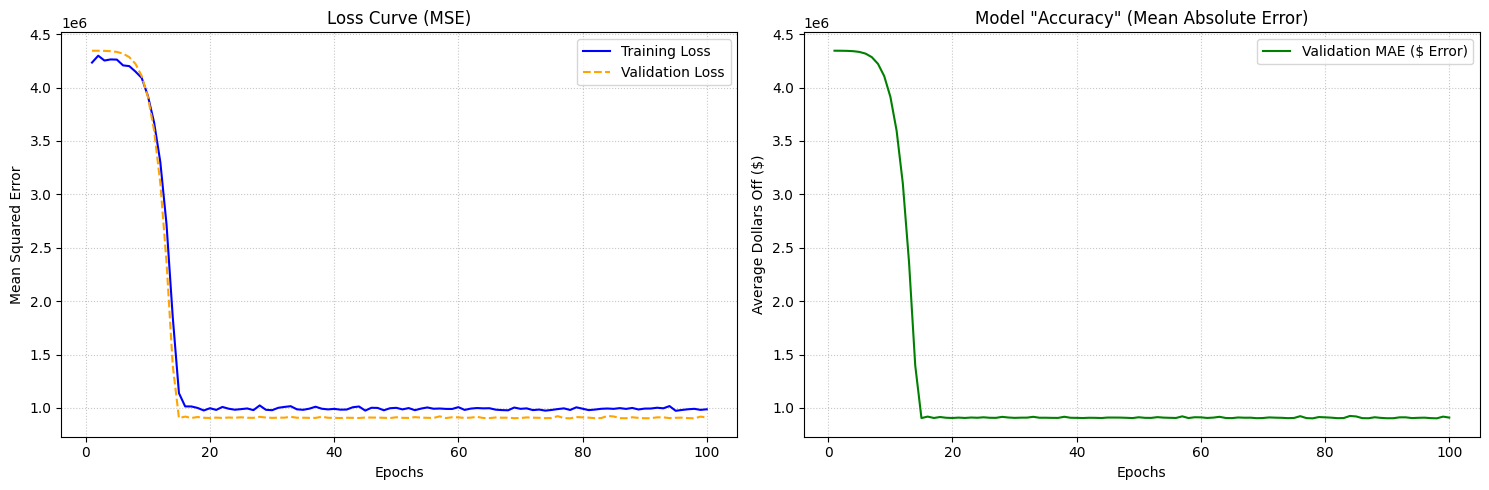

In [ ]:
import matplotlib.pyplot as plt
# PLOT LEARNING CURVES
# We create a figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: The Loss Curves (MSE)
axes[0].plot(range(1, EPOCHS + 1), train_losses, label='Training Loss', color='blue')
axes[0].plot(range(1, EPOCHS + 1), val_losses, label='Validation Loss', color='orange', linestyle='--')
axes[0].set_title('Loss Curve (MSE)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Mean Squared Error')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.7)

# Plot 2: The "Accuracy" Curve (Mean Absolute Error)
axes[1].plot(range(1, EPOCHS + 1), val_maes, label='Validation MAE ($ Error)', color='green')
axes[1].set_title('Model "Accuracy" (Mean Absolute Error)')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Average Dollars Off ($)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

# 🎯 **Visualizing the Predictions (Dots & Lines)**

Because our model uses 12 different features, we cannot draw a simple 2D "Line of Best Fit." The model is operating in 12-dimensional space!

To visualize how well our model tracks the true prices, we will use a **Sorted Overlay Plot**:
1. We sort all the houses in our test set from cheapest to most expensive.
2. We plot the **Actual Prices** as black dots.
3. We plot our **Model's Predictions** as a continuous red line.

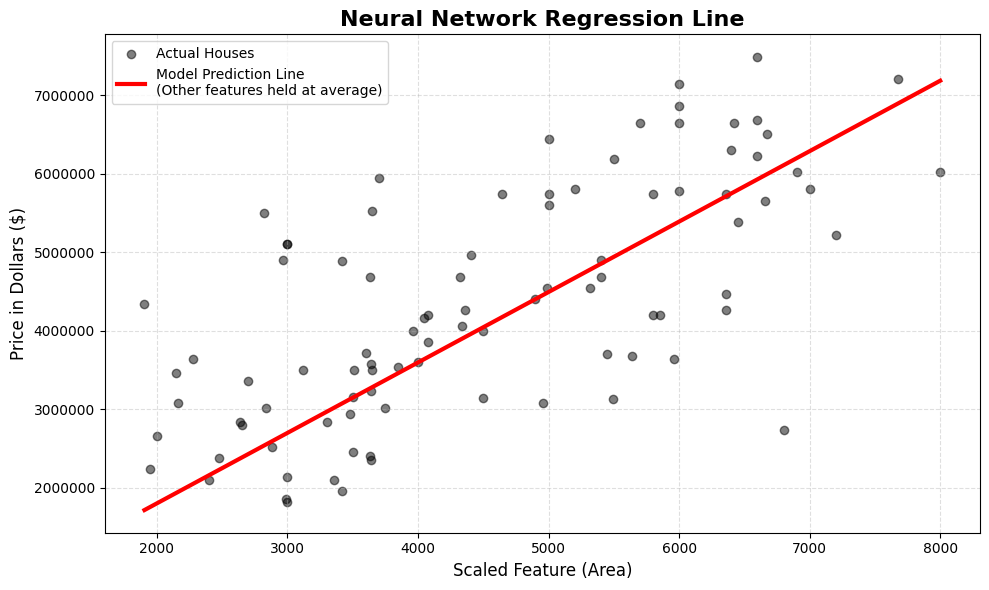

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# VISUALIZE THE REGRESSION LINE
model.eval()

# 1. Choose ONE feature to plot on the X-axis (Feature 0 is usually 'Area')
FEATURE_INDEX = 0

# Extract the actual scaled values for this feature and the true prices
x_actual = X_test_tensor[:, FEATURE_INDEX].numpy()
y_actual = y_test_tensor.numpy()

# 2. Create synthetic data to draw the Model's Prediction Line
# We create 100 evenly spaced points from the minimum to the maximum area
x_line = np.linspace(x_actual.min(), x_actual.max(), 100)

# Create a blank grid for our 12 features, filled with zeros.
# Because we used StandardScaler, "0" represents the exact mathematical average!
synthetic_X = np.zeros((100, X_test_tensor.shape[1]))

# Insert our 100 points into the chosen feature's column
synthetic_X[:, FEATURE_INDEX] = x_line

# Convert to a PyTorch tensor and ask the model to predict the prices
synthetic_X_tensor = torch.tensor(synthetic_X, dtype=torch.float32).to(device)
with torch.no_grad():
    y_line = model(synthetic_X_tensor).cpu().numpy()

# 3. Plotting the Dots and the Line
plt.figure(figsize=(10, 6))

# Plot the real houses as black dots
plt.scatter(x_actual, y_actual, color='black', alpha=0.5, label='Actual Houses')

# Plot the model's prediction as a red line
plt.plot(x_line, y_line, color='red', linewidth=3, label='Model Prediction Line\n(Other features held at average)')

plt.title('Neural Network Regression Line', fontsize=16, fontweight='bold')
plt.xlabel('Scaled Feature (Area)', fontsize=12)
plt.ylabel('Price in Dollars ($)', fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()